<a href="https://colab.research.google.com/github/bavucadoz/244107020162_ML_2026/blob/main/Minggu11/P02_Week11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Praktikum 2**
*Pada praktikum ke-2 ini, kita akan mencoba memanfaatkan SVM untuk mengklasifiaksikan data dengan distribusi non-linier. Dengan menggunakan kernel trick, SVM juga mampu membuat decision boundaries pada data non-linier.*


---



## **Langkah 1 - Ilustrasi Data Non-Linier**

**Langkah 1a - Import Library**

In [1]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

**Langkah 1b - Buat Kembali Fungsi Plotting**

In [3]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

**Langkah 1c - Buat Data Dummy Non-Linier**

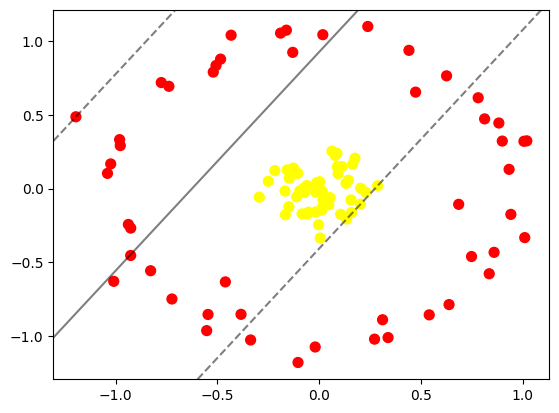

In [4]:
# contoh data tidak terpisah secara linier
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False);

In [6]:
# Mengubah plot visualisasi menjadi model 3D

r = np.exp(-(X ** 2).sum(1))

from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azip=(-180, 180),
         X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[ 0.22869482, -0.02434964],
       [ 0.685594  , -0.10688178],
       [ 0.14392804,  0.05698059],
       [-0.15669354,  0.12738753],
       [-0.07954184, -0.010622  ],
       [-0.02135255,  0.01399201],
       [ 1.00624323,  0.32118489],
       [ 0.94197144, -0.17511269],
       [-0.16087989,  1.07570974],
       [-0.18936117,  1.05590056],
       [ 0.0791966 ,  0.2249719 ],
       [-0.38372711, -0.85385959],
       [-0.0192801 , -1.07557267],
       [ 0.1595434 , -0.16300576],
       [-1.03976909,  0.10323262],
       [ 0.06307182,  0.25418346],
       [ 0.9333165 ,  0.13073854],
       [-0.73811824,  0.69473373],
       [-0.0561968 , -0.17170777],
       [-0.29395772, -0.05781837],
       [-0.98022764,  0.33240269],
       [-0.92556249, -0.26828722],
       [ 0.15652826, -0.07677089],
       [-0.12584226,  0.13913191],
       [ 0.85957823, -0.43288584],
       [ 0.20378673,  0.0022029 ],
       [-0.11059884, -0.05605431],
       [-0.21780617,  0.12230173],
       [-0.1676138 , -0.01659581],
       [-0.43240151,  1.04155132],
       [-0.5201458 ,  0.79094893],
       [ 0.0898279 ,  0.14922417],
       [ 0.11247916,  0.14953596],
       [-0.12957484,  0.92503125],
       [ 0.89985557,  0.32266782],
       [ 0.01893939, -0.07594409],
       [ 0.54090762, -0.85741115],
       [-0.08320561, -0.17205968],
       [ 0.00543809, -0.33574463],
       [-0.14652186,  0.07112021],
       [ 0.05344303, -0.06145346],
       [-1.19498806,  0.48757083],
       [ 0.63828826, -0.78769921],
       [-0.05163685, -0.15977253],
       [ 1.02029737,  0.32418944],
       [-0.50655322,  0.83593629],
       [-0.24988203,  0.04983587],
       [ 0.27223053, -1.02238288],
       [ 0.88306871,  0.44535543],
       [-0.77551776,  0.72006256],
       [-0.72317123, -0.74971798],
       [-0.16567675, -0.17784309],
       [-0.33661876, -1.02796914],
       [-0.01159177,  0.04099448],
       [-0.10487862,  0.10351611],
       [ 0.33873039, -1.0116561 ],
       [-0.55243901, -0.96436848],
       [ 0.47391007,  0.65503924],
       [-0.14860763, -0.12314137],
       [-0.48419893,  0.87920453],
       [-0.07285934, -0.02695081],
       [-0.92585953, -0.45419775],
       [ 0.13228076,  0.0356499 ],
       [-0.54583496, -0.85469711],
       [ 0.00327037,  0.04674502],
       [-0.93709756, -0.24348641],
       [ 0.01254184, -0.14708849],
       [ 0.20291631, -0.10591155],
       [ 0.4412618 ,  0.93868737],
       [ 0.6261125 ,  0.76573019],
       [ 0.13525007, -0.20679029],
       [ 0.8130544 ,  0.47328571],
       [-0.82776642, -0.55790407],
       [-0.05988111,  0.02038254],
       [-1.02392498,  0.16758628],
       [-0.46062402, -0.63370744],
       [-0.97697215,  0.2920017 ],
       [ 0.74871538, -0.46126448],
       [ 0.28741827,  0.01933038],
       [ 0.04786561, -0.10967287],
       [ 0.78142079,  0.61676204],
       [-0.00238815, -0.24573553],
       [-0.10376543, -1.18080296],
       [ 0.01530618, -0.01777173],
       [ 0.0869408 ,  0.24033829],
       [ 0.0929024 ,  0.10175338],
       [ 0.17591923,  0.20606352],
       [ 0.16482454,  0.16503708],
       [ 0.23911833,  1.10083038],
       [-0.01716695, -0.02313605],
       [ 0.01414737, -0.13319176],
       [-0.09503376, -0.01602529],
       [ 0.01814363,  1.04494493],
       [-0.01658242, -0.1581748 ],
       [-1.00898953, -0.6297095 ],
       [ 0.83570871, -0.57835896],
       [ 1.01021494, -0.33287744],
       [ 0.10538232, -0.1744934 ],
       [ 0.3116478 , -0.89064041],
       [-0.07467011,  0.00316268]]), y=array([1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0,
       1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1,
       0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1]))>



---

## **Langkah 2 - Fitting Model**

In [7]:
# Menggunakan kernel radial basis function (RBF) pada Scikit-Learn

clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

SVC(C=1000000.0)

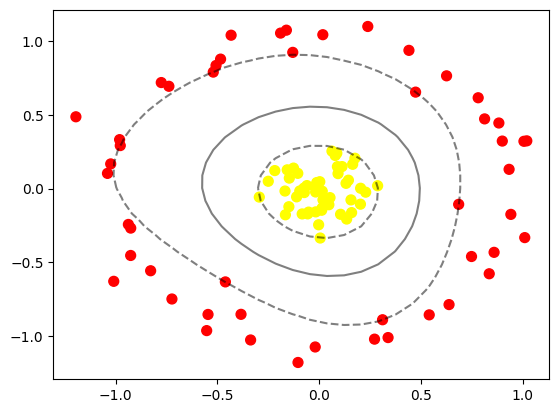

In [8]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')